In [1]:
!pip install numpy matplotlib tensorflow

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt

# ============================================================
# im2col / col2im: convert sliding-window operations (convolution,
# pooling) into matrix multiplication.
# This is the standard trick for implementing CNNs efficiently in
# NumPy -- a naive 4-nested-loop convolution would be far too slow.
# ============================================================

def im2col(x, kh, kw, stride=1):
    """
    Unfold each sliding window of the input into a single row.
    Input  x  : (N, C, H, W)
    Output col: (N*out_h*out_w, C*kh*kw)
    This lets convolution be computed as a single matmul: col @ W.T
    """
    N, C, H, W = x.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1

    col = np.zeros((N, C, kh, kw, out_h, out_w), dtype=x.dtype)
    for y in range(kh):
        y_max = y + stride * out_h
        for xx in range(kw):
            x_max = xx + stride * out_w
            col[:, :, y, xx, :, :] = x[:, :, y:y_max:stride, xx:x_max:stride]

    # reorder axes, then flatten into a 2D matrix
    col = col.transpose(0, 4, 5, 1, 2, 3).reshape(N * out_h * out_w, -1)
    return col, out_h, out_w


def col2im(col, input_shape, kh, kw, stride=1):
    """
    Inverse of im2col. Used during backprop to fold gradients back
    into the original image shape.
    Note: overlapping window regions must be ACCUMULATED (+=),
    not overwritten.
    """
    N, C, H, W = input_shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1

    col = col.reshape(N, out_h, out_w, C, kh, kw).transpose(0, 3, 4, 5, 1, 2)
    img = np.zeros((N, C, H, W), dtype=col.dtype)
    for y in range(kh):
        y_max = y + stride * out_h
        for xx in range(kw):
            x_max = xx + stride * out_w
            img[:, :, y:y_max:stride, xx:x_max:stride] += col[:, :, y, xx, :, :]
    return img

In [4]:
# quick sanity check: confirm im2col output shape is as expected
test_x = np.random.rand(2, 1, 6, 6)  # 2 images, 1 channel, 6x6
col, out_h, out_w = im2col(test_x, kh=3, kw=3, stride=1)
print("input shape:", test_x.shape)
print("col shape:", col.shape, "| out_h:", out_h, "| out_w:", out_w)

input shape: (2, 1, 6, 6)
col shape: (32, 9) | out_h: 4 | out_w: 4


In [5]:
class Conv2D:
    """Valid convolution, stride 1, implemented via im2col."""

    def __init__(self, in_channels, out_channels, kernel_size):
        self.kh = self.kw = kernel_size
        self.in_c = in_channels
        self.out_c = out_channels

        # He initialization: good default for layers followed by ReLU
        fan_in = in_channels * kernel_size * kernel_size
        self.W = np.random.randn(out_channels, in_channels, kernel_size, kernel_size) * np.sqrt(2.0 / fan_in)
        self.b = np.zeros(out_channels)

        # gradient placeholders, filled in during backward()
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self._cache = None  # stores values needed for backward pass

    def forward(self, x):
        N, C, H, W = x.shape
        col, out_h, out_w = im2col(x, self.kh, self.kw, stride=1)
        W2 = self.W.reshape(self.out_c, -1)  # flatten filters: (out_c, C*kh*kw)

        out = col @ W2.T + self.b            # (N*out_h*out_w, out_c)
        out = out.reshape(N, out_h, out_w, self.out_c).transpose(0, 3, 1, 2)

        self._cache = (x.shape, col)  # save for backward
        return out

    def backward(self, dout):
        x_shape, col = self._cache
        N, C, H, W = x_shape

        # reshape incoming gradient to match the flattened forward-pass layout
        dout2 = dout.transpose(0, 2, 3, 1).reshape(-1, self.out_c)  # (N*out_h*out_w, out_c)

        self.db = dout2.sum(axis=0)
        dW2 = dout2.T @ col                    # (out_c, C*kh*kw)
        self.dW = dW2.reshape(self.W.shape)

        W2 = self.W.reshape(self.out_c, -1)
        dcol = dout2 @ W2                       # (N*out_h*out_w, C*kh*kw)
        dx = col2im(dcol, x_shape, self.kh, self.kw, stride=1)
        return dx

    def params_and_grads(self):
        # used later by the SGD update step
        return [(self.W, self.dW), (self.b, self.db)]

In [6]:
# quick sanity check: confirm Conv2D output shape matches architecture spec
# input: 4 images, 1 channel, 28x28 -> Conv1 should give 6 channels, 26x26
conv1_test = Conv2D(in_channels=1, out_channels=6, kernel_size=3)
test_input = np.random.rand(4, 1, 28, 28)
test_out = conv1_test.forward(test_input)
print("conv1 output shape:", test_out.shape)

conv1 output shape: (4, 6, 26, 26)


In [7]:
class ReLU:
    """Rectified Linear Unit activation: f(x) = max(0, x)"""

    def __init__(self):
        self._mask = None

    def forward(self, x):
        self._mask = (x > 0)  # remember which entries were positive
        return x * self._mask

    def backward(self, dout):
        # gradient passes through only where the input was positive
        return dout * self._mask


class MaxPool2D:
    """Non-overlapping max pooling, implemented via im2col reused per-channel."""

    def __init__(self, pool_size=2, stride=2):
        self.p = pool_size
        self.s = stride
        self._cache = None

    def forward(self, x):
        N, C, H, W = x.shape
        # treat each channel independently by folding it into the batch dimension
        x_reshaped = x.reshape(N * C, 1, H, W)
        col, out_h, out_w = im2col(x_reshaped, self.p, self.p, self.s)  # (N*C*out_h*out_w, p*p)

        arg = np.argmax(col, axis=1)               # index of the max value in each window
        out = col[np.arange(col.shape[0]), arg]     # the max value itself
        out = out.reshape(N, C, out_h, out_w)

        self._cache = (x.shape, arg, col.shape, out_h, out_w)
        return out

    def backward(self, dout):
        x_shape, arg, col_shape, out_h, out_w = self._cache
        N, C, H, W = x_shape

        dout_flat = dout.reshape(-1)
        dcol = np.zeros(col_shape, dtype=dout.dtype)
        # route each gradient value only to the position that was the max during forward
        dcol[np.arange(col_shape[0]), arg] = dout_flat

        dx = col2im(dcol, (N * C, 1, H, W), self.p, self.p, self.s)
        return dx.reshape(N, C, H, W)

In [8]:
# quick sanity check: ReLU + MaxPool2D shapes, using the conv1 output from Cell 2
relu1_test = ReLU()
pool1_test = MaxPool2D(pool_size=2, stride=2)

relu_out = relu1_test.forward(test_out)     # test_out came from conv1 in Cell 2, shape (4, 6, 26, 26)
pool_out = pool1_test.forward(relu_out)
print("after ReLU shape:", relu_out.shape)
print("after MaxPool shape:", pool_out.shape)

after ReLU shape: (4, 6, 26, 26)
after MaxPool shape: (4, 6, 13, 13)


In [9]:
# quick sanity check: verify Conv2 + Pool2 dimensions match the architecture spec
conv2_test = Conv2D(in_channels=6, out_channels=16, kernel_size=3)
relu2_test = ReLU()
pool2_test = MaxPool2D(pool_size=2, stride=2)

conv2_out = conv2_test.forward(pool_out) 
relu2_out = relu2_test.forward(conv2_out)
pool2_out = pool2_test.forward(relu2_out)

print("conv2 output shape:", conv2_out.shape)
print("after ReLU shape:", relu2_out.shape)
print("after MaxPool shape:", pool2_out.shape)

conv2 output shape: (4, 16, 11, 11)
after ReLU shape: (4, 16, 11, 11)
after MaxPool shape: (4, 16, 5, 5)


In [10]:
class Flatten:
    """Reshape (N, C, H, W) -> (N, C*H*W) so it can feed into a fully connected layer."""

    def __init__(self):
        self._shape = None

    def forward(self, x):
        self._shape = x.shape  # remember original shape for backward
        return x.reshape(x.shape[0], -1)

    def backward(self, dout):
        return dout.reshape(self._shape)


class FullyConnected:
    """Standard dense layer: out = x @ W + b"""

    def __init__(self, in_features, out_features):
        self.W = np.random.randn(in_features, out_features) * np.sqrt(2.0 / in_features)
        self.b = np.zeros(out_features)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self._x = None

    def forward(self, x):
        self._x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self._x.T @ dout
        self.db = dout.sum(axis=0)
        return dout @ self.W.T

    def params_and_grads(self):
        return [(self.W, self.dW), (self.b, self.db)]


def softmax(logits):
    # subtract max for numerical stability (avoids overflow in exp)
    z = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(z)
    return exp / exp.sum(axis=1, keepdims=True)


class SoftmaxCrossEntropy:
    """Combines softmax activation + cross-entropy loss (numerically stable)."""

    def __init__(self):
        self._probs = None
        self._labels = None

    def forward(self, logits, labels):
        # labels: integer class indices, shape (N,)
        probs = softmax(logits)
        N = logits.shape[0]
        log_likelihood = -np.log(np.clip(probs[np.arange(N), labels], 1e-12, 1.0))
        loss = log_likelihood.mean()

        self._probs, self._labels = probs, labels
        return loss, probs

    def backward(self):
        # gradient of softmax + cross-entropy combined simplifies to (probs - one_hot) / N
        N = self._probs.shape[0]
        dlogits = self._probs.copy()
        dlogits[np.arange(N), self._labels] -= 1
        dlogits /= N
        return dlogits

In [11]:
# quick sanity check: Flatten -> FC1 -> ReLU -> FC2 -> Softmax+CrossEntropy
flatten_test = Flatten()
fc1_test = FullyConnected(in_features=16*5*5, out_features=128)
relu3_test = ReLU()
fc2_test = FullyConnected(in_features=128, out_features=10)
loss_fn_test = SoftmaxCrossEntropy()

flat_out = flatten_test.forward(pool2_out)   # pool2_out came from Cell 4, shape (4, 16, 5, 5)
fc1_out = fc1_test.forward(flat_out)
relu3_out = relu3_test.forward(fc1_out)
logits = fc2_test.forward(relu3_out)

fake_labels = np.array([3, 7, 1, 9])  # 4 fake labels, matching batch size 4
loss, probs = loss_fn_test.forward(logits, fake_labels)

print("flatten shape:", flat_out.shape)
print("fc1 output shape:", fc1_out.shape)
print("logits shape:", logits.shape)
print("loss:", loss)
print("probs sum per row (should all be ~1.0):", probs.sum(axis=1))

flatten shape: (4, 400)
fc1 output shape: (4, 128)
logits shape: (4, 10)
loss: 3.1894189652795553
probs sum per row (should all be ~1.0): [1. 1. 1. 1.]


In [12]:
class SimpleCNN:
    def __init__(self, lr=0.01):
        self.lr = lr

        self.conv1 = Conv2D(1, 6, 3)
        self.relu1 = ReLU()
        self.pool1 = MaxPool2D(2, 2)

        self.conv2 = Conv2D(6, 16, 3)
        self.relu2 = ReLU()
        self.pool2 = MaxPool2D(2, 2)

        self.flatten = Flatten()
        self.fc1 = FullyConnected(16 * 5 * 5, 128)
        self.relu3 = ReLU()
        self.fc2 = FullyConnected(128, 10)

        self.loss_fn = SoftmaxCrossEntropy()

        # layers with learnable parameters, in forward order (used by SGD step)
        self._param_layers = [self.conv1, self.conv2, self.fc1, self.fc2]

    def forward(self, x):
        out = self.conv1.forward(x)
        out = self.relu1.forward(out)
        out = self.pool1.forward(out)

        out = self.conv2.forward(out)
        out = self.relu2.forward(out)
        out = self.pool2.forward(out)

        out = self.flatten.forward(out)
        out = self.fc1.forward(out)
        out = self.relu3.forward(out)
        logits = self.fc2.forward(out)
        return logits

    def backward(self):
        # walk backward through the exact reverse order of forward()
        dout = self.loss_fn.backward()
        dout = self.fc2.backward(dout)
        dout = self.relu3.backward(dout)
        dout = self.fc1.backward(dout)
        dout = self.flatten.backward(dout)

        dout = self.pool2.backward(dout)
        dout = self.relu2.backward(dout)
        dout = self.conv2.backward(dout)

        dout = self.pool1.backward(dout)
        dout = self.relu1.backward(dout)
        self.conv1.backward(dout)

    def sgd_step(self):
        # vanilla stochastic gradient descent: param -= lr * grad
        for layer in self._param_layers:
            for param, grad in layer.params_and_grads():
                param -= self.lr * grad

    def train_step(self, x_batch, y_batch):
        logits = self.forward(x_batch)
        loss, probs = self.loss_fn.forward(logits, y_batch)
        self.backward()
        self.sgd_step()
        acc = (probs.argmax(axis=1) == y_batch).mean()
        return loss, acc

    def predict(self, x, batch_size=256):
        preds = []
        for i in range(0, x.shape[0], batch_size):
            logits = self.forward(x[i:i + batch_size])
            preds.append(logits.argmax(axis=1))
        return np.concatenate(preds)

In [13]:
# quick sanity check: run a few train_steps on random fake data to confirm
# the full forward+backward+SGD pipeline works end-to-end (no real MNIST needed yet)
np.random.seed(0)
fake_x = np.random.rand(32, 1, 28, 28).astype(np.float32)
fake_y = np.random.randint(0, 10, size=32)

model = SimpleCNN(lr=0.01)
for step in range(5):
    loss, acc = model.train_step(fake_x, fake_y)
    print(f"step {step+1}: loss={loss:.4f}, acc={acc:.4f}")

step 1: loss=2.3587, acc=0.1875
step 2: loss=2.1743, acc=0.2188
step 3: loss=2.0827, acc=0.2812
step 4: loss=2.0401, acc=0.3750
step 5: loss=2.0191, acc=0.3438


In [14]:
def load_mnist():
    """
    Load MNIST via keras (falls back to torchvision, then sklearn) and
    apply the required preprocessing:
      - normalize pixel values to [0, 1]
      - reshape to (N, 1, 28, 28)
    """
    try:
        from tensorflow.keras.datasets import mnist
        (x_train, y_train), (x_test, y_test) = mnist.load_data()
    except Exception:
        try:
            from torchvision import datasets
            train_ds = datasets.MNIST(root="./data", train=True, download=True)
            test_ds = datasets.MNIST(root="./data", train=False, download=True)
            x_train, y_train = train_ds.data.numpy(), train_ds.targets.numpy()
            x_test, y_test = test_ds.data.numpy(), test_ds.targets.numpy()
        except Exception:
            from sklearn.datasets import fetch_openml
            mnist_data = fetch_openml("mnist_784", version=1, as_frame=False)
            X = mnist_data["data"].reshape(-1, 28, 28).astype(np.uint8)
            y = mnist_data["target"].astype(np.int64)
            x_train, x_test = X[:60000], X[60000:]
            y_train, y_test = y[:60000], y[60000:]

    # normalize to [0, 1] and reshape to (N, 1, 28, 28)
    x_train = x_train.astype(np.float32) / 255.0
    x_test = x_test.astype(np.float32) / 255.0
    x_train = x_train.reshape(-1, 1, 28, 28)
    x_test = x_test.reshape(-1, 1, 28, 28)
    y_train = y_train.astype(np.int64)
    y_test = y_test.astype(np.int64)

    return x_train, y_train, x_test, y_test

In [15]:
print("Loading and preprocessing MNIST...")
x_train, y_train, x_test, y_test = load_mnist()
print(f"Train: {x_train.shape}, Test: {x_test.shape}")
print(f"Pixel value range: [{x_train.min()}, {x_train.max()}]")

Loading and preprocessing MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 
Train: (60000, 1, 28, 28), Test: (10000, 1, 28, 28)
Pixel value range: [0.0, 1.0]


In [16]:
def train(model, x_train, y_train, x_test, y_test,
          epochs=5, batch_size=32, verbose=True):
    n = x_train.shape[0]
    history = {"loss": [], "acc": []}

    for epoch in range(epochs):
        t0 = time.time()
        # shuffle the training data at the start of every epoch
        perm = np.random.permutation(n)
        x_train, y_train = x_train[perm], y_train[perm]

        epoch_loss, epoch_acc, n_batches = 0.0, 0.0, 0
        for i in range(0, n, batch_size):
            xb = x_train[i:i + batch_size]
            yb = y_train[i:i + batch_size]
            loss, acc = model.train_step(xb, yb)
            epoch_loss += loss
            epoch_acc += acc
            n_batches += 1

        epoch_loss /= n_batches
        epoch_acc /= n_batches
        history["loss"].append(epoch_loss)
        history["acc"].append(epoch_acc)

        if verbose:
            dt = time.time() - t0
            print(f"Epoch {epoch + 1}/{epochs} - Loss: {epoch_loss:.4f}, "
                  f"Accuracy: {epoch_acc:.4f} ({dt:.1f}s)")

    test_preds = model.predict(x_test)
    test_acc = (test_preds == y_test).mean()
    print(f"Test Accuracy: {test_acc:.4f}")

    return history, test_acc


def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history["loss"], marker="o")
    axes[0].set_title("Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")

    axes[1].plot(history["acc"], marker="o", color="green")
    axes[1].set_title("Training Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")

    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=150)
    plt.show()
    print("Saved training curves to training_curves.png")

In [17]:
# smoke test on a small subset first, before committing to the full run
np.random.seed(42)
x_train_small, y_train_small = x_train[:2000], y_train[:2000]
x_test_small, y_test_small = x_test[:500], y_test[:500]

model_test = SimpleCNN(lr=0.01)
history_test, test_acc_test = train(model_test, x_train_small, y_train_small,
                                     x_test_small, y_test_small,
                                     epochs=2, batch_size=32)

Epoch 1/2 - Loss: 2.1260, Accuracy: 0.3080 (0.7s)
Epoch 2/2 - Loss: 1.3513, Accuracy: 0.6349 (0.7s)
Test Accuracy: 0.7320


In [18]:
np.random.seed(42)

model = SimpleCNN(lr=0.01)
history, test_acc = train(model, x_train, y_train, x_test, y_test,
                           epochs=5, batch_size=32)

Epoch 1/5 - Loss: 0.4151, Accuracy: 0.8745 (22.7s)
Epoch 2/5 - Loss: 0.1478, Accuracy: 0.9548 (22.5s)
Epoch 3/5 - Loss: 0.1078, Accuracy: 0.9676 (22.5s)
Epoch 4/5 - Loss: 0.0878, Accuracy: 0.9728 (22.5s)
Epoch 5/5 - Loss: 0.0755, Accuracy: 0.9769 (22.4s)
Test Accuracy: 0.9777


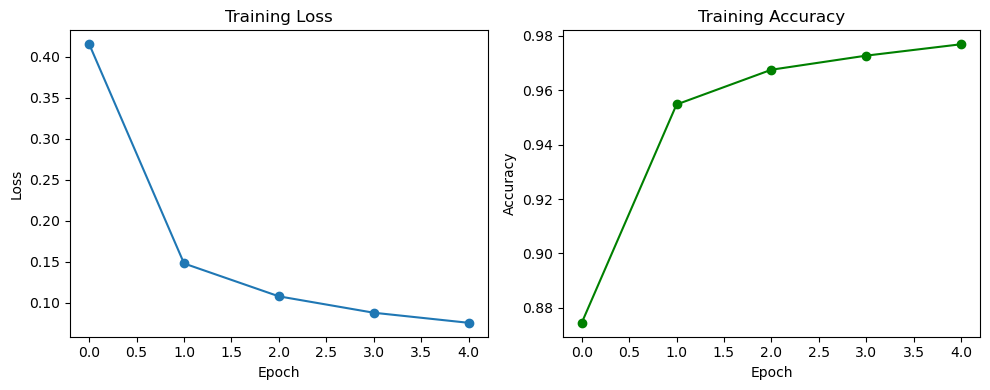

Saved training curves to training_curves.png


In [19]:
plot_history(history)